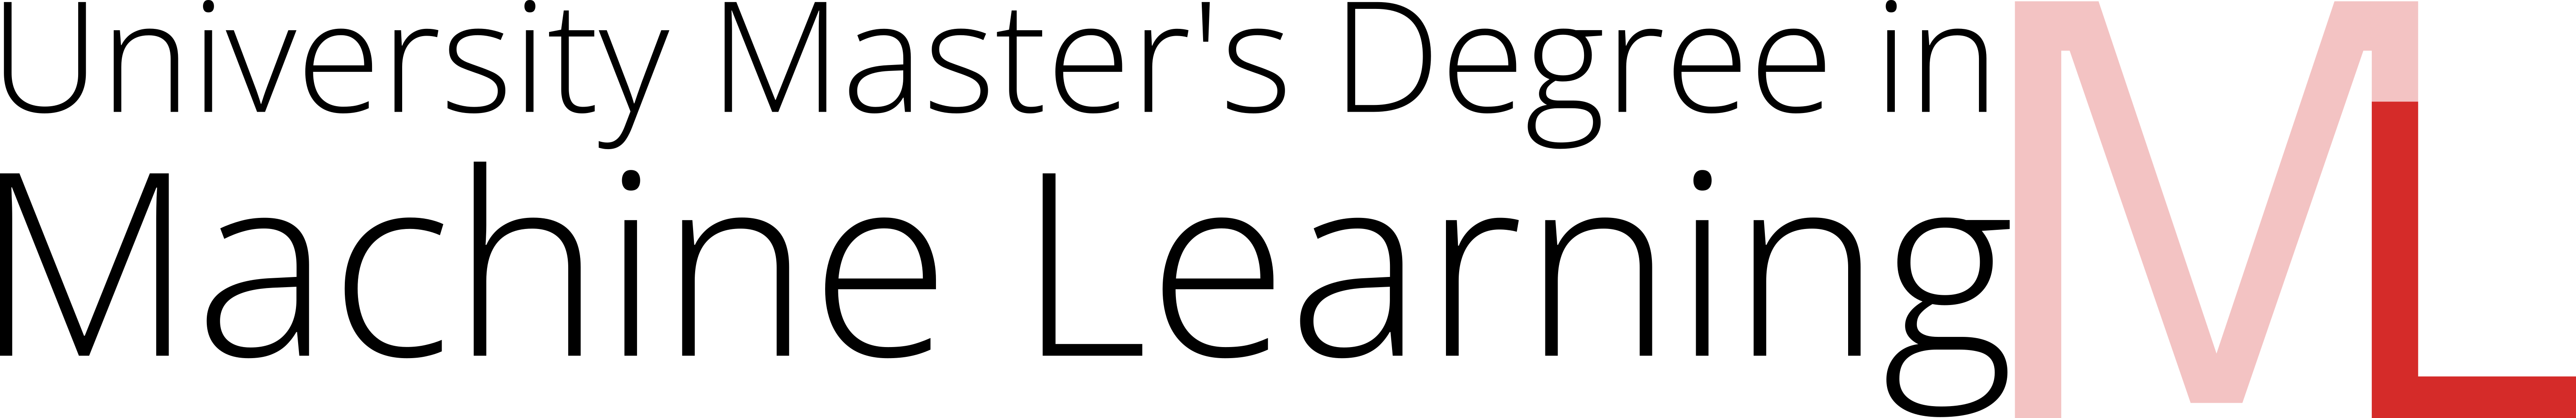

Now let’s move on to building deep neural network models with more than one hidden layer. To do this, we will reuse the **HiddenLayer** class we created earlier. Using it, generate again the **MLP** class, but this time the constructor will take as input parameters:

* **input\_size**
* **hidden\_sizes** (a list containing the number of neurons for each hidden layer)
* **output\_size**

The parameter **hidden\_sizes** specifies the structure of the hidden layers. For example:

* `hidden_sizes = [256]` → a neural network with **one hidden layer** of 256 neurons.
* `hidden_sizes = [256, 128, 64]` → a neural network with **three hidden layers** of 256, 128, and 64 neurons, respectively.

Recall that you can use `nn.ModuleList` to work with a list of models.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


In [2]:
class HiddenLayer(nn.Module):
  def __init__(self, input_size, hidden_size):
    super(HiddenLayer, self).__init__()
    self.W = nn.Parameter(torch.randn(input_size, hidden_size))
    self.b = nn.Parameter(torch.zeros(1, hidden_size))

  def forward(self, X):
    return torch.matmul(X, self.W) + self.b


In [3]:
class MLP(nn.Module):
    ##YOUR CODE HERE
    def __init__(self, input_size, hidden_sizes, output_size):
        super(MLP, self).__init__()
        self.hidden_layers = nn.ModuleList()

        current_imput_size = input_size
        for hidden_size in hidden_sizes:
            hidden_layer = HiddenLayer(current_imput_size, hidden_size)
            self.hidden_layers.append(hidden_layer)
            current_imput_size = hidden_size
            
        self.output_layer = HiddenLayer(current_imput_size, output_size)

        
    def forward(self, X):
        current_input = X
        for hidden_layer in self.hidden_layers:
            Z = hidden_layer(current_input)
            current_input = torch.relu(Z)
        
        out = self.output_layer(current_input)
        return out

Once the model is created, get some data generated by the given code and try to learn neural networks to fit the data (regression). Compare the use of one-hidden layer NN with neural networks of more thatn you layers. Once generated, divide the data intro train and test (80/20) and compare the results in each corresponding set. 


In [4]:
def generate_function(n_points=1000, noise=0.1):

    X = torch.linspace(-5, 5, n_points).unsqueeze(1)
    on = torch.sin(X) * 2
    pi = -4 * torch.exp(-((X - 2)**2) / 0.1)
    te = 0.5 * X
    y = on + pi + te

    y += noise * torch.randn(y.shape)
    return X, y

In [5]:
X, y = generate_function()

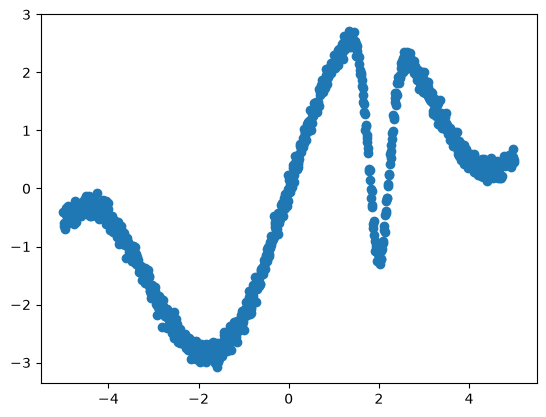

In [6]:
plt.scatter(X.numpy(), y.numpy())
plt.show()

In [7]:
num_samples = len(X)
indices = torch.randperm(num_samples)
train_size = int(0.8 * num_samples)

train_idx, test_idx = indices[:train_size], indices[train_size:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

In [8]:
# 1. Asegurar que X e y son tensores de tipo float32
X_train = torch.as_tensor(X_train, dtype=torch.float32)
y_train = torch.as_tensor(y_train, dtype=torch.float32)
X_test = torch.as_tensor(X_test, dtype=torch.float32)
y_test = torch.as_tensor(y_test, dtype=torch.float32)

# 2. Verificar los tipos de datos (deben imprimir torch.float32)
print("Tipo de X_train:", type(X_train), X_train.dtype)
print("Tipo de y_train:", type(y_train), y_train.dtype)

Tipo de X_train: <class 'torch.Tensor'> torch.float32
Tipo de y_train: <class 'torch.Tensor'> torch.float32


In [9]:
def train_model(model, X_train, y_train, epochs=1000, lr=0.01):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    y_train = y_train.float()

    for epoch in range(epochs):
        model.train()

        y_pred = model(X_train)
        loss = criterion(y_pred, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

    return model

In [10]:
input_size= X_train.shape[1]

model_single = MLP(X_train.shape[1], hidden_sizes=[64], output_size=1)
train_model(model_single, X_train, y_train, epochs=1200, lr=0.01)

model_deep = MLP(X_train.shape[1], hidden_sizes=[64, 32, 16], output_size=1)
train_model(model_deep, X_train, y_train, epochs=1200, lr=0.01)

Epoch [100/1200], Loss: 0.7300
Epoch [200/1200], Loss: 0.5655
Epoch [300/1200], Loss: 0.4614
Epoch [400/1200], Loss: 0.3978
Epoch [500/1200], Loss: 0.3738
Epoch [600/1200], Loss: 0.3662
Epoch [700/1200], Loss: 0.3635
Epoch [800/1200], Loss: 0.3624
Epoch [900/1200], Loss: 0.3618
Epoch [1000/1200], Loss: 0.3613
Epoch [1100/1200], Loss: 0.3610
Epoch [1200/1200], Loss: 0.3607
Epoch [100/1200], Loss: 2.3055
Epoch [200/1200], Loss: 1.0384
Epoch [300/1200], Loss: 0.5492
Epoch [400/1200], Loss: 0.4021
Epoch [500/1200], Loss: 0.3702
Epoch [600/1200], Loss: 0.3624
Epoch [700/1200], Loss: 0.3597
Epoch [800/1200], Loss: 0.3582
Epoch [900/1200], Loss: 0.3571
Epoch [1000/1200], Loss: 0.3562
Epoch [1100/1200], Loss: 0.3554
Epoch [1200/1200], Loss: 0.3546


MLP(
  (hidden_layers): ModuleList(
    (0-2): 3 x HiddenLayer()
  )
  (output_layer): HiddenLayer()
)

--- Model Performance (MSE Loss) ---
Single Hidden Layer [64]:        Train MSE = 0.3607 | Test MSE = 0.2085
Multi Hidden Layer [64, 32, 16]: Train MSE = 0.3546 | Test MSE = 0.2034


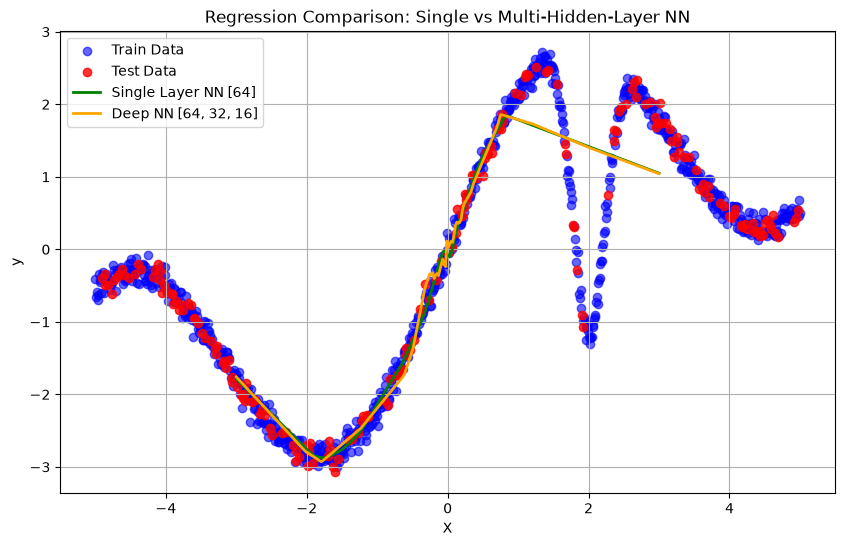

In [11]:
criterion = nn.MSELoss()

model_single.eval()
model_deep.eval()

with torch.no_grad():
    # Model Single Performance
    train_loss_single = criterion(model_single(X_train), y_train).item()
    test_loss_single = criterion(model_single(X_test), y_test).item()

    # Model Deep Performance
    train_loss_deep = criterion(model_deep(X_train), y_train).item()
    test_loss_deep = criterion(model_deep(X_test), y_test).item()

    # Predictions for Plotting
    X_plot = torch.linspace(-3, 3, 300).unsqueeze(1)
    y_plot_single = model_single(X_plot)
    y_plot_deep = model_deep(X_plot)

# Output Performance Summary
print("--- Model Performance (MSE Loss) ---")
print(f"Single Hidden Layer [64]:        Train MSE = {train_loss_single:.4f} | Test MSE = {test_loss_single:.4f}")
print(f"Multi Hidden Layer [64, 32, 16]: Train MSE = {train_loss_deep:.4f} | Test MSE = {test_loss_deep:.4f}")

# Plot Dataset and Model Regressions
plt.figure(figsize=(10, 6))
plt.scatter(X_train.numpy(), y_train.numpy(), color='blue', alpha=0.6, label='Train Data')
plt.scatter(X_test.numpy(), y_test.numpy(), color='red', alpha=0.8, label='Test Data')
plt.plot(X_plot.numpy(), y_plot_single.numpy(), color='green', linewidth=2, label='Single Layer NN [64]')
plt.plot(X_plot.numpy(), y_plot_deep.numpy(), color='orange', linewidth=2, label='Deep NN [64, 32, 16]')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Regression Comparison: Single vs Multi-Hidden-Layer NN')
plt.legend()
plt.grid(True)
plt.show()

# A more compact way to write our code


So far, we have been programming most of our models **from scratch**. This methodology is not only useful in the learning process, but it also gives us great flexibility to develop models tailored to our needs.

However, in many cases we don’t need so much customization, and we can program in a much more compact way.




### nn.Linear

`nn.Linear` is a PyTorch class that represents a fully connected (or "dense") layer in a neural network. This layer applies a linear transformation to the input data using parameters $W$ and $b$. When instantiating it, you must specify the number of inputs (`in_features`) and the number of outputs (`out_features`), which define the dimensions of the transformation. It is one of the fundamental layers in multilayer perceptron (MLP) models and other neural network architectures.


### nn.Sequential

`nn.Sequential` is a class in PyTorch that allows chaining multiple layers or modules (`nn.Module`) in the order they are defined, forming a composite model. When you pass an input tensor, it automatically flows through each layer in sequence. This is useful for building simple architectures where the data flow is strictly linear.

There are several ways to construct an `nn.Sequential`:

* **Passing the layers directly into the constructor**

```python
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)
```

* **Using a predefined list of layers (with `*`)**

```python
layers = [
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
]

model = nn.Sequential(*layers)
```

* **Using an `OrderedDict` with custom names**

```python
from collections import OrderedDict

model = nn.Sequential(OrderedDict([
    ('fc1', nn.Linear(784, 128)),
    ('relu1', nn.ReLU()),
    ('fc2', nn.Linear(128, 64)),
    ('relu2', nn.ReLU()),
    ('fc3', nn.Linear(64, 10))
]))
```

This allows you to access layers by name:

```python
print(model['fc1'])  # Accesses the first linear layer
```



### Assignment


---

**AssignmentTh, this assignment focuses on conducting a more detailed analysis using a more complex dataset: **Fashion-MNIST**. This dataset comprises **70,000 grayscale images of dimension 28 × 28 pixels**, representing **10 distinct classes**: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, and Ankle booThe task consists of two main components:

- **Dataset Analysis**: Perform an initial exploration and analysis of the dataset, highlighting its main characteristics and potential challenges for classification.
- **Model Evaluation**: Design and evaluate several neural network architectures (at least 2), ranging from shallow networks with a single hidden layer to deeper models. You may compare networks with a similar total number of parameters but a different number of hidden layers, so that depth and capacity are not confounded. Your analysis should examine convergence behavior and classification accuracy, both on the training and test sets.

Repeat each configuration with at least 3 different random seeds and report mean ± standard deviation. State explicitly which of the observed differences you consider real and which fall within run-to-run variability.

Submit a report of 1-2 pages. This report will be later extended after the regularization session. in length.


In [49]:
data = torch.load('fashion_mnist.pt')

X_train = data['X_train'] #X_train.max() = 1. >>> valores de 0 a 1
y_train = data['y_train'] #torch.unique(y_train) = 0, 1, 2, 3, 4, 5, 6, 7, 8, 9
X_test = data['X_test']
y_test = data['y_test']

print(f"X_train shape: {X_train.shape}, dtype: {X_train.dtype}") #X_train shape: torch.Size([60000, 784]), dtype: torch.float32
print(f"y_train shape: {y_train.shape}, dtype: {y_train.dtype}") #y_train shape: torch.Size([60000]), dtype: torch.int64

X_train shape: torch.Size([60000, 784]), dtype: torch.float32
y_train shape: torch.Size([60000]), dtype: torch.int64


In [51]:
input_size = X_train.shape[1] #784
output_size = len(torch.unique(y_train)) #10

one_layer = [
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Linear(128, output_size)
]

two_layer = [
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, output_size)
]

three_layer = [
    nn.Linear(input_size, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, output_size)
]

In [54]:

# 4. Resumen de Resultados
print("=================== RESULTADOS FULL-BATCH ===================")
print(f"Shallow MLP [1 Capa]:  Train Acc = {np.mean(shallow_tr):.2f}% ± {np.std(shallow_tr):.2f}% | Test Acc = {np.mean(shallow_te):.2f}% ± {np.std(shallow_te):.2f}%")
print(f"Deep MLP    [3 Capas]: Train Acc = {np.mean(deep_tr):.2f}% ± {np.std(deep_tr):.2f}% | Test Acc = {np.mean(deep_te):.2f}% ± {np.std(deep_te):.2f}%")

=================== RESULTADOS FULL-BATCH ===================
Shallow MLP [1 Capa]:  Train Acc = 88.28% ± 0.18% | Test Acc = 86.30% ± 0.27%
Deep MLP    [3 Capas]: Train Acc = 88.31% ± 0.12% | Test Acc = 86.47% ± 0.15%


--- Entrenando Modelo: 1 Capa Oculta ---
Seed 42 | [==============================] 300/300 Epochs - Loss: 0.3373
Seed 100 | [==============================] 300/300 Epochs - Loss: 0.3323
Seed 2026 | [==============================] 300/300 Epochs - Loss: 0.3338

--- Entrenando Modelo: 2 Capas Ocultas ---
Seed 42 | [==============================] 300/300 Epochs - Loss: 0.3206
Seed 100 | [==============================] 300/300 Epochs - Loss: 0.3222
Seed 2026 | [==============================] 300/300 Epochs - Loss: 0.3115

--- Entrenando Modelo: 3 Capas Ocultas ---
Seed 42 | [==============================] 300/300 Epochs - Loss: 0.2939
Seed 100 | [==============================] 300/300 Epochs - Loss: 0.2835
Seed 2026 | [==============================] 300/300 Epochs - Loss: 0.2868

=================== RESULTADOS COMPARATIVOS ===================
1 Capa Oculta  [128]:       Train: 88.48% ± 0.16% | Test: 86.27% ± 0.17%
2 Capas Ocultas [128, 64]:   Train: 88.89% ± 0.14% | Test: 86.94% ±

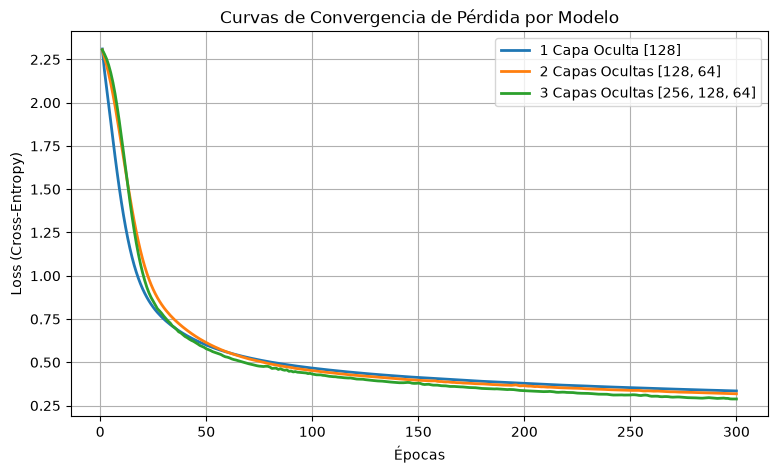

In [55]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# 1. Definición de parámetros de entrada/salida
input_size = X_train.shape[1]
output_size = len(torch.unique(y_train))

# 2. Funciones para instanciar modelos nuevos con pesos iniciales limpios por semilla
make_one_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Linear(128, output_size)
)

make_two_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, output_size)
)

make_three_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, output_size)
)

# 3. Función de entrenamiento adaptada
def train_and_eval_full_batch(model_builder, input_size, output_size, seeds=[42, 100, 2026], epochs=300, lr=0.001):
    train_accs, test_accs = [], []
    all_losses = []  # Guarda las pérdidas por época para cada semilla
    criterion = nn.CrossEntropyLoss()

    for seed in seeds:
        torch.manual_seed(seed)
        # Construye una instancia nueva con pesos limpios
        model = model_builder()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        seed_losses = []

        for epoch in range(epochs):
            model.train()
            optimizer.zero_grad()
            
            outputs = model(X_train)
            loss = criterion(outputs, y_train)
            
            loss.backward()
            optimizer.step()

            seed_losses.append(loss.item())

            if (epoch + 1) % 10 == 0 or epoch == epochs - 1:
                progress = int(30 * (epoch + 1) / epochs)
                bar = "=" * progress + "-" * (30 - progress)
                print(f"\rSeed {seed} | [{bar}] {epoch+1}/{epochs} Epochs - Loss: {loss.item():.4f}", end="")

        print() # Nueva línea al terminar la semilla
        all_losses.append(seed_losses)

        model.eval()
        with torch.no_grad():
            preds_tr = model(X_train).argmax(dim=1)
            acc_tr = (preds_tr == y_train).float().mean().item() * 100
            train_accs.append(acc_tr)

            preds_te = model(X_test).argmax(dim=1)
            acc_te = (preds_te == y_test).float().mean().item() * 100
            test_accs.append(acc_te)

    return train_accs, test_accs, all_losses

# 4. Ejecutar comparación de las 3 arquitecturas
seeds = [42, 100, 2026]

print("--- Entrenando Modelo: 1 Capa Oculta ---")
m1_tr, m1_te, m1_losses = train_and_eval_full_batch(make_one_layer, input_size, output_size, seeds=seeds)

print("\n--- Entrenando Modelo: 2 Capas Ocultas ---")
m2_tr, m2_te, m2_losses = train_and_eval_full_batch(make_two_layer, input_size, output_size, seeds=seeds)

print("\n--- Entrenando Modelo: 3 Capas Ocultas ---")
m3_tr, m3_te, m3_losses = train_and_eval_full_batch(make_three_layer, input_size, output_size, seeds=seeds)

# 5. Imprimir Resumen Estadístico (Media ± Desviación Estándar)
print("\n=================== RESULTADOS COMPARATIVOS ===================")
print(f"1 Capa Oculta  [128]:       Train: {np.mean(m1_tr):.2f}% ± {np.std(m1_tr):.2f}% | Test: {np.mean(m1_te):.2f}% ± {np.std(m1_te):.2f}%")
print(f"2 Capas Ocultas [128, 64]:   Train: {np.mean(m2_tr):.2f}% ± {np.std(m2_tr):.2f}% | Test: {np.mean(m2_te):.2f}% ± {np.std(m2_te):.2f}%")
print(f"3 Capas Ocultas [256,128,64]: Train: {np.mean(m3_tr):.2f}% ± {np.std(m3_tr):.2f}% | Test: {np.mean(m3_te):.2f}% ± {np.std(m3_te):.2f}%")

# 6. Graficar curvas de pérdida promedio
plt.figure(figsize=(9, 5))
plt.plot(range(1, 301), np.mean(m1_losses, axis=0), label='1 Capa Oculta [128]', linewidth=2)
plt.plot(range(1, 301), np.mean(m2_losses, axis=0), label='2 Capas Ocultas [128, 64]', linewidth=2)
plt.plot(range(1, 301), np.mean(m3_losses, axis=0), label='3 Capas Ocultas [256, 128, 64]', linewidth=2)
plt.xlabel('Épocas')
plt.ylabel('Loss (Cross-Entropy)')
plt.title('Curvas de Convergencia de Pérdida por Modelo')
plt.legend()
plt.grid(True)
plt.show()

--- Training Model: 1 Hidden Layer ---
Seed 42 | [==============================] 1000/1000 Epochs - Loss: 0.2116
Seed 100 | [==============================] 1000/1000 Epochs - Loss: 0.2145
Seed 2026 | [==============================] 1000/1000 Epochs - Loss: 0.2134

--- Training Model: 2 Hidden Layers ---
Seed 42 | [==============================] 1000/1000 Epochs - Loss: 0.2041
Seed 100 | [==============================] 1000/1000 Epochs - Loss: 0.1993
Seed 2026 | [==============================] 1000/1000 Epochs - Loss: 0.1913

--- Training Model: 3 Hidden Layers ---
Seed 42 | [==============================] 1000/1000 Epochs - Loss: 0.1664
Seed 100 | [==============================] 1000/1000 Epochs - Loss: 0.1487
Seed 2026 | [==============================] 1000/1000 Epochs - Loss: 0.1517

=================== COMPARATIVE RESULTS ===================
1 Hidden Layer  [128]:       Train: 92.61% ± 0.05% | Test: 87.95% ± 0.19%
2 Hidden Layers [128, 64]:   Train: 92.97% ± 0.24% | Test: 8

ValueError: x and y must have same first dimension, but have shapes (300,) and (1000,)

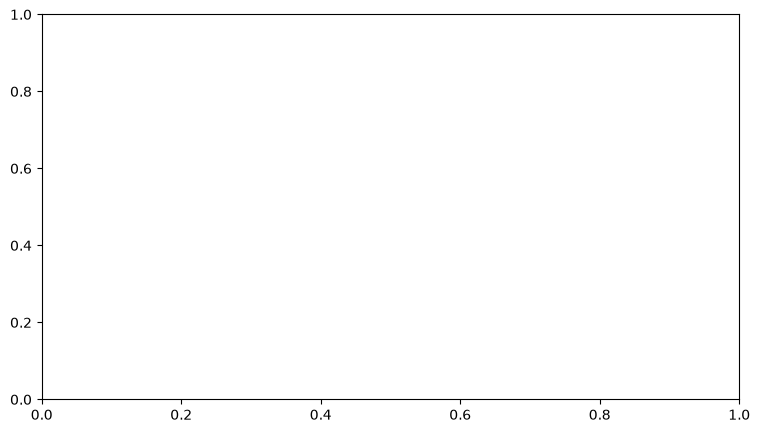

In [57]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# 1. Load Data
data = torch.load('fashion_mnist.pt')

X_train = data['X_train'].float()
y_train = data['y_train'].long()
X_test = data['X_test'].float()
y_test = data['y_test'].long()

# Define input/output dimensions
input_size = X_train.shape[1]
output_size = len(torch.unique(y_train))

# 2. Builder Functions for Fresh Model Instances per Seed
make_one_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Linear(128, output_size)
)

make_two_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, output_size)
)

make_three_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, output_size)
)

# 3. Full-Batch Training Function with Progress Bar & Loss Tracking
def train_and_eval_full_batch(model_builder, input_size, output_size, seeds=[42, 100, 2026], epochs=1000, lr=0.001):
    train_accs, test_accs = [], []
    all_losses = []  # Stores epoch loss lists per seed: [[loss_seed1...], [loss_seed2...]]
    criterion = nn.CrossEntropyLoss()

    for seed in seeds:
        torch.manual_seed(seed)
        # Instantiate fresh model weights per seed
        model = model_builder()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        seed_losses = []

        for epoch in range(epochs):
            model.train()
            optimizer.zero_grad()
            
            outputs = model(X_train)
            loss = criterion(outputs, y_train)
            
            loss.backward()
            optimizer.step()

            # Record loss float value for current epoch
            seed_losses.append(loss.item())

            # Textual progress bar updated in-place
            if (epoch + 1) % 10 == 0 or epoch == epochs - 1:
                progress = int(30 * (epoch + 1) / epochs)
                bar = "=" * progress + "-" * (30 - progress)
                print(f"\rSeed {seed} | [{bar}] {epoch+1}/{epochs} Epochs - Loss: {loss.item():.4f}", end="")

        print()  # Newline after each seed completes
        all_losses.append(seed_losses)

        # Evaluation phase
        model.eval()
        with torch.no_grad():
            preds_tr = model(X_train).argmax(dim=1)
            acc_tr = (preds_tr == y_train).float().mean().item() * 100
            train_accs.append(acc_tr)

            preds_te = model(X_test).argmax(dim=1)
            acc_te = (preds_te == y_test).float().mean().item() * 100
            test_accs.append(acc_te)

    return train_accs, test_accs, all_losses

# 4. Run Comparative Benchmarks
seeds = [42, 100, 2026]

print("--- Training Model: 1 Hidden Layer ---")
m1_tr, m1_te, m1_losses = train_and_eval_full_batch(make_one_layer, input_size, output_size, seeds=seeds)

print("\n--- Training Model: 2 Hidden Layers ---")
m2_tr, m2_te, m2_losses = train_and_eval_full_batch(make_two_layer, input_size, output_size, seeds=seeds)

print("\n--- Training Model: 3 Hidden Layers ---")
m3_tr, m3_te, m3_losses = train_and_eval_full_batch(make_three_layer, input_size, output_size, seeds=seeds)

# 5. Output Summary Results (Mean ± Std Dev)
print("\n=================== COMPARATIVE RESULTS ===================")
print(f"1 Hidden Layer  [128]:       Train: {np.mean(m1_tr):.2f}% ± {np.std(m1_tr):.2f}% | Test: {np.mean(m1_te):.2f}% ± {np.std(m1_te):.2f}%")
print(f"2 Hidden Layers [128, 64]:   Train: {np.mean(m2_tr):.2f}% ± {np.std(m2_tr):.2f}% | Test: {np.mean(m2_te):.2f}% ± {np.std(m2_te):.2f}%")
print(f"3 Hidden Layers [256,128,64]: Train: {np.mean(m3_tr):.2f}% ± {np.std(m3_tr):.2f}% | Test: {np.mean(m3_te):.2f}% ± {np.std(m3_te):.2f}%")



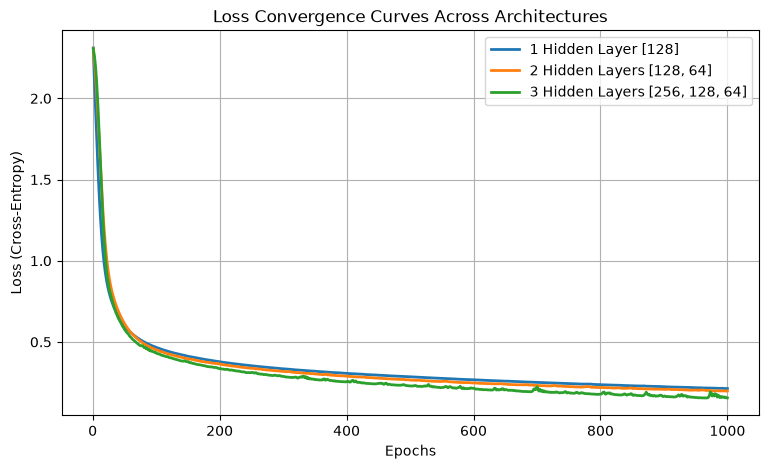

In [59]:
# 6. Plot Convergence Loss Curves
epochs = len(m1_losses[0])

plt.figure(figsize=(9, 5))

plt.plot(range(1, epochs + 1), np.mean(m1_losses, axis=0),
         label='1 Hidden Layer [128]', linewidth=2)

plt.plot(range(1, epochs + 1), np.mean(m2_losses, axis=0),
         label='2 Hidden Layers [128, 64]', linewidth=2)

plt.plot(range(1, epochs + 1), np.mean(m3_losses, axis=0),
         label='3 Hidden Layers [256, 128, 64]', linewidth=2)

plt.xlabel('Epochs')
plt.ylabel('Loss (Cross-Entropy)')
plt.title('Loss Convergence Curves Across Architectures')
plt.legend()
plt.grid(True)
plt.show()

In [60]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# 1. Carga de datos
data = torch.load('fashion_mnist.pt')
X_train = data['X_train'].float()
y_train = data['y_train'].long()
X_test = data['X_test'].float()
y_test = data['y_test'].long()

input_size = X_train.shape[1]
output_size = len(torch.unique(y_train))

# 2. Constructores de Modelos Iso-Parámetricos (~102k Parámetros)
make_one_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Linear(128, output_size)
)

make_two_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 118),
    nn.ReLU(),
    nn.Linear(118, 80),
    nn.ReLU(),
    nn.Linear(80, output_size)
)

make_three_layer = lambda: nn.Sequential(
    nn.Linear(input_size, 112),
    nn.ReLU(),
    nn.Linear(112, 80),
    nn.ReLU(),
    nn.Linear(80, 50),
    nn.ReLU(),
    nn.Linear(50, output_size)
)

# 3. Función de Entrenamiento con SGD
def train_and_eval_full_batch(model_builder, seeds=[42, 100, 2026], epochs=1000, lr=0.1):
    train_accs, test_accs = [], []
    all_losses = []
    criterion = nn.CrossEntropyLoss()

    for seed in seeds:
        torch.manual_seed(seed)
        model = model_builder()
        # Uso explícito de SGD con Momentum
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

        seed_losses = []

        for epoch in range(epochs):
            model.train()
            optimizer.zero_grad()
            
            outputs = model(X_train)
            loss = criterion(outputs, y_train)
            
            loss.backward()
            optimizer.step()

            seed_losses.append(loss.item())

            if (epoch + 1) % 100 == 0 or epoch == epochs - 1:
                progress = int(30 * (epoch + 1) / epochs)
                bar = "=" * progress + "-" * (30 - progress)
                print(f"\rSeed {seed} | [{bar}] {epoch+1}/{epochs} Epochs - Loss: {loss.item():.4f}", end="")

        print()
        all_losses.append(seed_losses)

        # Evaluación final
        model.eval()
        with torch.no_grad():
            preds_tr = model(X_train).argmax(dim=1)
            acc_tr = (preds_tr == y_train).float().mean().item() * 100
            train_accs.append(acc_tr)

            preds_te = model(X_test).argmax(dim=1)
            acc_te = (preds_te == y_test).float().mean().item() * 100
            test_accs.append(acc_te)

    return train_accs, test_accs, all_losses

# 4. Ejecución del Benchmark
seeds = [42, 100, 2026]

print("--- Modelo 1 Capa Oculta (~101.7k params) ---")
m1_tr, m1_te, m1_losses = train_and_eval_full_batch(make_one_layer, seeds=seeds)

print("\n--- Modelo 2 Capas Ocultas (~102.9k params) ---")
m2_tr, m2_te, m2_losses = train_and_eval_full_batch(make_two_layer, seeds=seeds)

print("\n--- Modelo 3 Capas Ocultas (~101.9k params) ---")
m3_tr, m3_te, m3_losses = train_and_eval_full_batch(make_three_layer, seeds=seeds)

# 5. Despliegue de Resultados
print("\n=================== RESULTADOS ISO-PARÁMETRICOS (SGD) ===================")
print(f"1 Capa Oculta  [128]:       Train: {np.mean(m1_tr):.2f}% ± {np.std(m1_tr):.2f}% | Test: {np.mean(m1_te):.2f}% ± {np.std(m1_te):.2f}%")
print(f"2 Capas Ocultas [118, 80]:   Train: {np.mean(m2_tr):.2f}% ± {np.std(m2_tr):.2f}% | Test: {np.mean(m2_te):.2f}% ± {np.std(m2_te):.2f}%")
print(f"3 Capas Ocultas [112,80,50]: Train: {np.mean(m3_tr):.2f}% ± {np.std(m3_tr):.2f}% | Test: {np.mean(m3_te):.2f}% ± {np.std(m3_te):.2f}%")

--- Modelo 1 Capa Oculta (~101.7k params) ---
Seed 42 | [==============================] 1000/1000 Epochs - Loss: 0.2592
Seed 100 | [==============================] 1000/1000 Epochs - Loss: 0.2591
Seed 2026 | [==============================] 1000/1000 Epochs - Loss: 0.2478

--- Modelo 2 Capas Ocultas (~102.9k params) ---
Seed 42 | [==============================] 1000/1000 Epochs - Loss: 0.1926
Seed 100 | [==============================] 1000/1000 Epochs - Loss: 0.2107
Seed 2026 | [==============================] 1000/1000 Epochs - Loss: 0.2161

--- Modelo 3 Capas Ocultas (~101.9k params) ---
Seed 42 | [==============================] 1000/1000 Epochs - Loss: 0.3205
Seed 100 | [==============================] 1000/1000 Epochs - Loss: 0.2107
Seed 2026 | [==============================] 1000/1000 Epochs - Loss: 0.2659

=================== RESULTADOS ISO-PARÁMETRICOS (SGD) ===================
1 Capa Oculta  [128]:       Train: 91.05% ± 0.41% | Test: 87.62% ± 0.27%
2 Capas Ocultas [118, 80

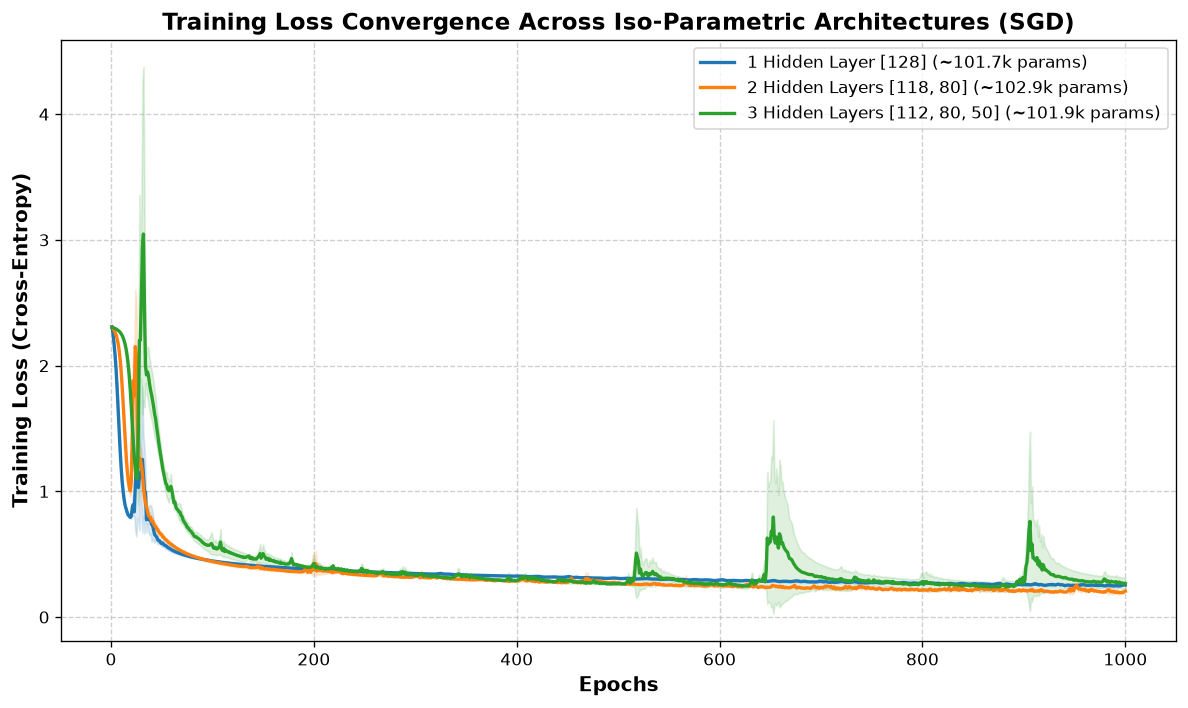

In [61]:
import matplotlib.pyplot as plt
import numpy as np

# Convert lists to NumPy arrays for easy calculation: shape -> (num_seeds, num_epochs)
m1_loss_arr = np.array(m1_losses)
m2_loss_arr = np.array(m2_losses)
m3_loss_arr = np.array(m3_losses)

# Calculate mean and standard deviation per epoch
m1_mean, m1_std = np.mean(m1_loss_arr, axis=0), np.std(m1_loss_arr, axis=0)
m2_mean, m2_std = np.mean(m2_loss_arr, axis=0), np.std(m2_loss_arr, axis=0)
m3_mean, m3_std = np.mean(m3_loss_arr, axis=0), np.std(m3_loss_arr, axis=0)

epochs = range(1, len(m1_mean) + 1)

# Set up publication-quality plot
plt.figure(figsize=(10, 6), dpi=120)

# Plot Mean Loss Curves
plt.plot(epochs, m1_mean, label='1 Hidden Layer [128] (~101.7k params)', color='#1f77b4', linewidth=2)
plt.plot(epochs, m2_mean, label='2 Hidden Layers [118, 80] (~102.9k params)', color='#ff7f0e', linewidth=2)
plt.plot(epochs, m3_mean, label='3 Hidden Layers [112, 80, 50] (~101.9k params)', color='#2ca02c', linewidth=2)

# Add shaded region for Run-to-Run Variability (±1 Standard Deviation)
plt.fill_between(epochs, m1_mean - m1_std, m1_mean + m1_std, color='#1f77b4', alpha=0.15)
plt.fill_between(epochs, m2_mean - m2_std, m2_mean + m2_std, color='#ff7f0e', alpha=0.15)
plt.fill_between(epochs, m3_mean - m3_std, m3_mean + m3_std, color='#2ca02c', alpha=0.15)

# Formatting labels and grid
plt.xlabel('Epochs', fontsize=12, fontweight='bold')
plt.ylabel('Training Loss (Cross-Entropy)', fontsize=12, fontweight='bold')
plt.title('Training Loss Convergence Across Iso-Parametric Architectures (SGD)', fontsize=14, fontweight='bold')
plt.legend(fontsize=10, loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Display plot
plt.show()